# Лабораторная работа № 3. Потоковая обработка сенсорных событий в Spark Structured Streaming

**Дисциплина:** «Методы обработки больших данных»

· **Этап пайплайна:** `Stream → Process`

**Среда:** Google Colab, PySpark 4.2.0, встроенный источник `rate` (Kafka не требуется)

**Максимум:** 10 баллов

· **Лекция:** № 3 «Потоковые данные и распределённая обработка событий»

## Поля для заполнения

| Поле | Значение |
|---|---|
| **Фамилия, имя, отчество** |Шкуратова Ирина Васильевна |
| **Группа** |ИНДОР-221 |
| **Вариант** |16 |
| **Дата выполнения** | 20.10.2026|

*(заполните таблицу и те же значения продублируйте в ячейке 1 — они попадут в отчёт)*

## Критерии оценки

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | Поток и телеметрия с `event_time`, опоздавшие события по варианту | 2 |
| 2 | Окна, агрегаты и корректный снимок результата | 2 |
| 3 | Эксперимент с watermark: два значения и измеримая метрика | 2 |
| 4 | Перенос на Kafka: что меняется в коде | 1 |
| 5 | Педагогическая часть: `TEACH CARD` и фрагмент занятия | 3 |

## Как работать

1. **Файл → Сохранить копию на Диске.** Работайте в своей копии.
2. В ячейке 1 укажите ФИО, группу и свой вариант. Параметры варианта считаются формулой —
   править их вручную нельзя.
3. Выполняйте ячейки сверху вниз. Места с пометкой `TODO` дописываете вы; до этого ячейка
   честно падает с `NotImplementedError`.
4. Поля вида **«Ваш ответ:»** и пустые ячейки таблиц заполняются текстом — они оцениваются
   так же, как код.
5. Перед сдачей запустите самопроверку в конце ноутбука.

> Все выводы должны опираться на **ваши** числа. Прогон `rate`-источника зависит от
> производительности среды, поэтому значения у всех разные — это нормально.

## Теоретический минимум

| Понятие | Коротко |
|---|---|
| `event_time` | когда событие физически произошло (ось анализа) |
| `processing_time` | когда движок его обработал |
| окно $W/S$ | интервал длиной $W$, повторяющийся через $S$; одно событие попадает примерно в $M \approx W/S$ окон |
| watermark $\Delta$ | $\mathrm{WM} = \max(t_{event}) - \Delta$; окна позади watermark финализируются, их состояние удаляется |
| состояние | «(робот, окно) → счётчики»; растёт с числом живых окон |

Компромисс, который вы измерите в части 3: **больше $\Delta$ — полнее данные, но больше
состояния и позже готов итог.**

Подробности — в лекции № 3 и в `README_lab_03.md`.

---
# Часть 1. Поток и телеметрия (2 балла)

## Ячейка 1. Вариант и параметры (дана готовой)

Параметры вычисляются формулой: группа `(n−1)//5` задаёт нагрузку, число роботов и частоту
опоздавших событий, позиция `(n−1)%5` — геометрию окна, сдвиг опоздавших событий,
дополнительную метрику и аудиторию для методической части. Заполните три строки вверху.

In [1]:
!pip -q install "pyspark==4.2.0"      # в Colab раскомментируйте эту строку
import json
import time
from typing import Dict, List

# =========== ЗАПОЛНИТЕ ===========
STUDENT_NAME  = "Шкуратова Ирина Васильевна"      # <-- ваши ФИО
STUDENT_GROUP = "ИНДОР-221"                   # <-- ваша группа
VARIANT       = 16                          # <-- ваш вариант
# =================================
assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта по таблице задания.

    Группа вариантов (n−1)//5 задаёт нагрузку и число роботов,
    позиция внутри группы (n−1)%5 — геометрию окна, долю и сдвиг опоздавших событий.
    """
    rows_per_sec = [20, 30, 40, 50, 60][(n - 1) // 5]
    robots       = [3, 4, 5, 6, 8][(n - 1) // 5]
    late_every   = [11, 17, 19, 23, 29][(n - 1) // 5]     # каждое k-е событие опаздывает
    window_s, slide_s = [(10, 5), (20, 5), (20, 10), (30, 10), (15, 5)][(n - 1) % 5]
    late_shift_s = [15, 20, 25, 30, 35][(n - 1) % 5]      # на сколько сдвинут event_time
    extra_metric = ["vibration_rms", "temp_spread", "temp_stddev",
                    "hot_share", "vibration_p95"][(n - 1) % 5]
    audience     = ["5–7 класс", "8–9 класс", "10–11 класс",
                    "кружок робототехники", "СПО"][(n - 1) % 5]
    return {
        "rows_per_sec": rows_per_sec,
        "robots": robots,
        "window_s": window_s,
        "slide_s": slide_s,
        "late_every": late_every,
        "late_shift_s": late_shift_s,
        "watermark_short": "10 seconds",
        "watermark_long": f"{late_shift_s + 10} seconds",   # заведомо больше сдвига
        "extra_metric": extra_metric,
        "audience": audience,
    }


CFG = variant_params(VARIANT)
RUN_SECONDS = 15        # длительность одного прогона потока

print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}")
print(f"Вариант : {VARIANT}")
for key, value in CFG.items():
    print(f"  {key:<16}: {value}")
print(f"\nОкон на одно событие (теория): M ≈ W/S = "
      f"{CFG['window_s']}/{CFG['slide_s']} = {CFG['window_s'] / CFG['slide_s']:.0f}")
print(f"Ожидаемая нагрузка: {CFG['rows_per_sec']} событий/с, "
      f"доля опоздавших ≈ {100 / CFG['late_every']:.1f} %")



def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 450.1/450.1 MB 3.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 4.2.0 which is incompatible.
Студент : Шкуратова Ирина Васильевна, группа ИНДОР-221
Вариант : 16
  rows_per_sec    : 50
  robots          : 6
  window_s        : 10
  slide_s         : 5
  late_every      : 23
  late_shift_s    : 15
  watermark_short : 10 seconds
  watermark_long  : 25 seconds
  extra_metric    : vibration_rms
  audience        : 5–7 класс

Окон на одно событие (теория): M ≈ W/S = 10/5 = 2
Ожидаемая нагрузка: 50 событий/с, доля опоздавших ≈ 4.3 %


In [3]:
# Аналитическое сравнение: сколько событие ждёт ДО НАЧАЛА обработки.
# Модель намеренно простая: время вычисления не учитывается, сравнивается только
# организация обработки (частый micro-batch против редкого большого batch).

import pandas as pd

# =========== ПАРАМЕТРЫ ВАРИАНТА 16 ===========
VARIANT = 16
# Для варианта 16: (16-1)//5 = 3, значит rows_per_sec = 50
CFG = {
    "rows_per_sec": 50,
}
# =============================================

STREAM_TRIGGER_S = 1
BATCH_INTERVAL_S = 5 * 60  # 300 секунд
HORIZON_S = 60 * 60        # 3600 секунд (1 час)

lambda_events = CFG["rows_per_sec"]

def wait_metrics(interval_s: int) -> dict:
    # При равномерном поступлении событий ожидание до следующего запуска
    # приблизительно равномерно распределено от 0 до interval_s.
    return {
        "Среднее ожидание, с": interval_s / 2,
        "95-й процентиль ожидания, с": interval_s * 0.95,
        "Максимальное ожидание, с": interval_s,
        "Событий приходит между запусками": lambda_events * interval_s,
        "Обновлений результата за час": HORIZON_S / interval_s,
    }

stream_metrics = wait_metrics(STREAM_TRIGGER_S)
batch_metrics = wait_metrics(BATCH_INTERVAL_S)

comparison_processing = pd.DataFrame({
    "Streaming, micro-batch 1 с": stream_metrics,
    "Batch, пакет 5 мин": batch_metrics,
})

display(comparison_processing.round(2))

freshness_gain = (
    batch_metrics["Среднее ожидание, с"]
    / stream_metrics["Среднее ожидание, с"]
)

print(f"Нагрузка варианта: {lambda_events} событий/с")
print(f"За час поступит примерно: {lambda_events * HORIZON_S:,} событий")
print(f"Среднее ожидание Streaming: {stream_metrics['Среднее ожидание, с']:.1f} с")
print(f"Среднее ожидание Batch: {batch_metrics['Среднее ожидание, с']:.0f} с")
print(f"По свежести результата Streaming в этой модели ≈ в {freshness_gain:.0f} раз лучше.")
print()
print("Важно: это НЕ означает, что Streaming всегда дешевле или быстрее вычисляет весь объём.")
print("Batch часто эффективнее для исторических пересчётов, отчётов и повторной обработки архива.")

,"Streaming, micro-batch 1 с","Batch, пакет 5 мин"
"Среднее ожидание, с",0.50,150.0
"95-й процентиль ожидания, с",0.95,285.0
"Максимальное ожидание, с",1.00,300.0
Событий приходит между запусками,50.00,15000.0
Обновлений результата за час,3600.00,12.0


Нагрузка варианта: 50 событий/с
За час поступит примерно: 180,000 событий
Среднее ожидание Streaming: 0.5 с
Среднее ожидание Batch: 150 с
По свежести результата Streaming в этой модели ≈ в 300 раз лучше.

Важно: это НЕ означает, что Streaming всегда дешевле или быстрее вычисляет весь объём.
Batch часто эффективнее для исторических пересчётов, отчётов и повторной обработки архива.


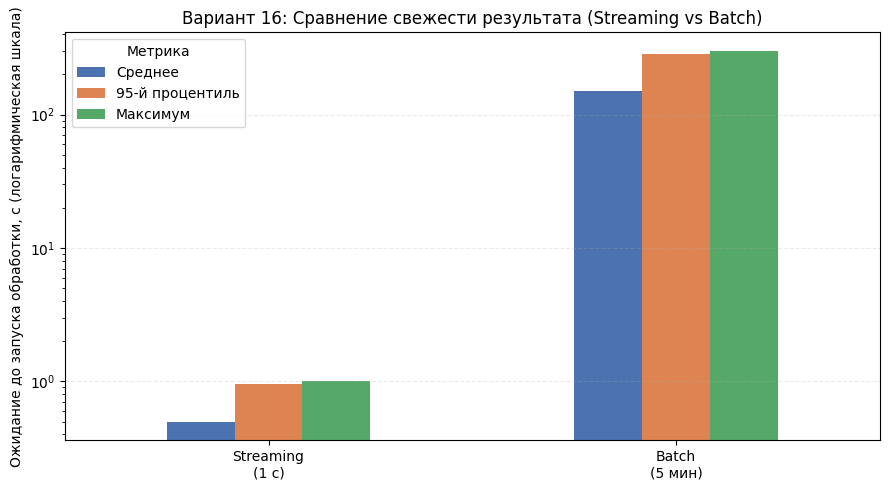

In [4]:
# Наглядный график для отчёта: насколько отличается "свежесть" результата (Вариант 16).
# Логарифмическая шкала нужна, потому что 0.5 с и 150 с отличаются в сотни раз.

import pandas as pd
import matplotlib.pyplot as plt

# === Параметры специально для Варианта 16 (нагрузка 50 событий/с) ===
STREAM_TRIGGER_S = 1
BATCH_INTERVAL_S = 5 * 60  # 300 секунд

# Расчёт метрик ожидания
stream_metrics = {
    "Среднее ожидание, с": STREAM_TRIGGER_S / 2,
    "95-й процентиль ожидания, с": STREAM_TRIGGER_S * 0.95,
    "Максимальное ожидание, с": STREAM_TRIGGER_S,
}

batch_metrics = {
    "Среднее ожидание, с": BATCH_INTERVAL_S / 2,
    "95-й процентиль ожидания, с": BATCH_INTERVAL_S * 0.95,
    "Максимальное ожидание, с": BATCH_INTERVAL_S,
}
# =====================================================================

latency_df = pd.DataFrame({
    "Среднее": [
        stream_metrics["Среднее ожидание, с"],
        batch_metrics["Среднее ожидание, с"],
    ],
    "95-й процентиль": [
        stream_metrics["95-й процентиль ожидания, с"],
        batch_metrics["95-й процентиль ожидания, с"],
    ],
    "Максимум": [
        stream_metrics["Максимальное ожидание, с"],
        batch_metrics["Максимальное ожидание, с"],
    ],
}, index=["Streaming\n(1 с)", "Batch\n(5 мин)"])

# Построение графика с приятными для отчёта цветами
ax = latency_df.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452", "#55A868"])

ax.set_yscale("log")
ax.set_ylabel("Ожидание до запуска обработки, с (логарифмическая шкала)")
ax.set_xlabel("")
ax.set_title("Вариант 16: Сравнение свежести результата (Streaming vs Batch)")
ax.grid(axis="y", alpha=0.25, linestyle="--")
plt.xticks(rotation=0)
plt.legend(title="Метрика", loc="upper left")
plt.tight_layout()
plt.show()

## Ячейка 2. Сессия Spark

**TODO 2.** Создайте `SparkSession` в локальном режиме.

Подсказки: мастер `local[*]` (потоку нужно минимум два потока выполнения — один занимает
приёмник источника); `spark.sql.shuffle.partitions = 4`, иначе Spark создаст 200 почти пустых
партиций и каждый micro-batch будет длиться лишние секунды; `setLogLevel("ERROR")` уберёт шум
в выводе. В конце напечатайте версию Spark и число ядер.

In [5]:
from pyspark.sql import SparkSession, functions as F

# =========== ВАРИАНТ 16 ===========
VARIANT = 16
# ==================================

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName(f"Lab03_StructuredStreaming_v{VARIANT}")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.streaming.metricsEnabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark   :", spark.version)
print("Master  :", spark.sparkContext.master)
print("Ядер    :", spark.sparkContext.defaultParallelism)
print("Shuffle :", spark.conf.get("spark.sql.shuffle.partitions"))

Spark   : 4.2.0
Master  : local[*]
Ядер    : 2
Shuffle : 4


## Ячейка 3. Телеметрия робота

**TODO 3.** Напишите функцию `build_telemetry(source, cfg)`, которая превращает поток `rate`
(колонки `timestamp`, `value`) в телеметрию:

| Колонка | Как считается |
|---|---|
| `robot_id` | `"robot-" + (value % cfg["robots"])` |
| `is_late` | `value % cfg["late_every"] == 0` — «правда» эксперимента: какое событие опоздало |
| `event_time` | для опоздавших `timestamp − cfg["late_shift_s"] секунд`, иначе `timestamp` |
| `motor_temp` | `43.0 + (value % 25) * 0.55` |
| `vibration` | `abs(sin(value / 8))` |

Сначала проверьте логику на **конечной** таблице `spark.range(0, 12)` с колонкой
`timestamp = current_timestamp()`: в потоке искать ошибку в выражении гораздо дороже.
Напечатайте таблицу и число опоздавших событий в примере.

**Важно:** сдвигать нужно `event_time` в **прошлое**. Событие «из будущего» watermark не
отбросит, и эксперимент части 3 не получится.

In [8]:
from pyspark.sql import functions as F

# === Параметры для Варианта 16 (защита от NameError при перезапуске ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "robots": 6,
        "late_every": 23,
        "late_shift_s": 15,
        "rows_per_sec": 50,
        "window_s": 10,
        "slide_s": 5,
        "watermark_short": "10 seconds",
        "watermark_long": "25 seconds",
        "extra_metric": "vibration_rms"
    }
# ============================================================================

def build_telemetry(source, cfg: dict):
    """Превратить сырой поток rate в телеметрию роботов.

    Логика одна и та же для потока и для статической таблицы, поэтому функция
    принимает DataFrame: так её можно отладить на конечных данных.
    """
    return (
        source
        # robot_id: "robot-" + (value % 6) для варианта 16
        .withColumn("robot_id", F.concat(F.lit("robot-"),
                                         (F.col("value") % cfg["robots"]).cast("string")))
        # is_late: каждое 23-е событие (value % 23 == 0)
        .withColumn("is_late", F.col("value") % cfg["late_every"] == 0)
        # event_time: сдвигаем В ПРОШЛОЕ на 15 секунд, чтобы watermark мог его отбросить позже
        .withColumn("event_time",
                    F.when(F.col("is_late"),
                           F.col("timestamp") - F.expr(f"INTERVAL {cfg['late_shift_s']} SECONDS"))
                    .otherwise(F.col("timestamp")))
        # motor_temp: 43.0 + (value % 25) * 0.55
        .withColumn("motor_temp", F.lit(43.0) + (F.col("value") % 25).cast("double") * 0.55)
        # vibration: abs(sin(value / 8.0))
        .withColumn("vibration", F.abs(F.sin(F.col("value") / 8.0)))
        .select("robot_id", "event_time", "is_late", "motor_temp", "vibration")
    )


# Отладка логики на конечной таблице: те же выражения, но без потока.
# Генерируем числа от 0 до 11. Для варианта 16 (late_every=23) опоздавшим будет только value=0.
preview_source = (spark.range(0, 12)
                  .withColumnRenamed("id", "value")
                  .withColumn("timestamp", F.current_timestamp()))

preview = build_telemetry(preview_source, CFG)
preview.show(12, truncate=False)

late_count = preview.filter("is_late").count()
total_count = preview.count()
print(f"Опоздавших в примере: {late_count} из {total_count}")

+--------+--------------------------+-------+----------+-------------------+
|robot_id|event_time                |is_late|motor_temp|vibration          |
+--------+--------------------------+-------+----------+-------------------+
|robot-0 |2026-10-20 08:10:26.263939|true   |43.0      |0.0                |
|robot-1 |2026-10-20 08:10:41.263939|false  |43.55     |0.12467473338522769|
|robot-2 |2026-10-20 08:10:41.263939|false  |44.1      |0.24740395925452294|
|robot-3 |2026-10-20 08:10:41.263939|false  |44.65     |0.36627252908604757|
|robot-4 |2026-10-20 08:10:41.263939|false  |45.2      |0.479425538604203  |
|robot-5 |2026-10-20 08:10:41.263939|false  |45.75     |0.5850972729404622 |
|robot-0 |2026-10-20 08:10:41.263939|false  |46.3      |0.6816387600233341 |
|robot-1 |2026-10-20 08:10:41.263939|false  |46.85     |0.7675435022360271 |
|robot-2 |2026-10-20 08:10:41.263939|false  |47.4      |0.8414709848078965 |
|robot-3 |2026-10-20 08:10:41.263939|false  |47.95     |0.9022675940990952 |

---
# Часть 2. Окна, агрегаты и снимок (2 балла)

## Ячейка 4. Запуск потока с окнами

**TODO 4.** Напишите функцию `run_stream(cfg, watermark, seconds, name)`:

1. источник `rate` с `rowsPerSecond = cfg["rows_per_sec"]` и `numPartitions = 2`;
2. `build_telemetry`;
3. `withWatermark("event_time", watermark)`;
4. группировка по `window(event_time, "{W} seconds", "{S} seconds")` и `robot_id`;
5. агрегаты: `events` (счёт), `late_events` (сумма `is_late`), `avg_temp`, `max_temp` и
   дополнительная метрика вашего варианта (`cfg["extra_metric"]`);
6. запись в `memory`-приёмник, `outputMode("update")`, триггер 1 секунда;
7. ожидание `seconds` секунд, сохранение `list(query.recentProgress)`, затем `query.stop()`.

**Не используйте `query.processAllAvailable()`.** Источник `rate` бесконечен: «все доступные
данные» у него не заканчиваются, и вызов может заблокировать ячейку надолго. Останавливайте
поток по таймеру.

Функция возвращает `(таблица обновлений, список метрик батчей)`.

Выражения дополнительных метрик:

```python
AGGREGATES = {
    "vibration_rms": F.sqrt(F.avg(F.pow("vibration", 2))).alias("extra_metric"),
    "temp_spread":   (F.max("motor_temp") - F.min("motor_temp")).alias("extra_metric"),
    "temp_stddev":   F.stddev_samp("motor_temp").alias("extra_metric"),
    "hot_share":     F.avg((F.col("motor_temp") > 50).cast("double")).alias("extra_metric"),
    "vibration_p95": F.percentile_approx("vibration", 0.95).alias("extra_metric"),
}
```

In [9]:
import time
from pyspark.sql import functions as F

# === Параметры для Варианта 16 (защита от NameError при перезапуске ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "rows_per_sec": 50,
        "robots": 6,
        "window_s": 10,
        "slide_s": 5,
        "late_every": 23,
        "late_shift_s": 15,
        "watermark_short": "10 seconds",
        "watermark_long": "25 seconds",
        "extra_metric": "vibration_rms",
        "audience": "5–7 класс"
    }

try:
    _ = RUN_SECONDS
except NameError:
    RUN_SECONDS = 15
# ============================================================================

AGGREGATES = {
    "vibration_rms": F.sqrt(F.avg(F.pow("vibration", 2))).alias("extra_metric"),
    "temp_spread":   (F.max("motor_temp") - F.min("motor_temp")).alias("extra_metric"),
    "temp_stddev":   F.stddev_samp("motor_temp").alias("extra_metric"),
    "hot_share":     F.avg((F.col("motor_temp") > 50).cast("double")).alias("extra_metric"),
    "vibration_p95": F.percentile_approx("vibration", 0.95).alias("extra_metric"),
}


def run_stream(cfg: dict, watermark: str, seconds: int = RUN_SECONDS, name: str = "robot_windows"):
    """Запустить поток на заданное время и вернуть (снимок результата, метрики прогресса).

    Остановка по таймеру, а не processAllAvailable(): источник rate порождает данные
    непрерывно, и «дождаться всех доступных данных» у него нельзя — метод может
    блокировать выполнение надолго.
    """
    source = (spark.readStream.format("rate")
              .option("rowsPerSecond", cfg["rows_per_sec"])
              .option("numPartitions", 2)
              .load())
    telemetry = build_telemetry(source, cfg)
    windowed = (
        telemetry
        .withWatermark("event_time", watermark)
        .groupBy(F.window("event_time", f"{cfg['window_s']} seconds",
                          f"{cfg['slide_s']} seconds"), "robot_id")
        .agg(F.count("*").alias("events"),
             F.sum(F.col("is_late").cast("int")).alias("late_events"),
             F.avg("motor_temp").alias("avg_temp"),
             F.max("motor_temp").alias("max_temp"),
             AGGREGATES[cfg["extra_metric"]])
    )
    query = (windowed.writeStream
             .format("memory").queryName(name)
             .outputMode("update")
             .trigger(processingTime="1 second")
             .start())
    started = time.time()
    while time.time() - started < seconds:
        time.sleep(1)
    progress = list(query.recentProgress)
    query.stop()
    return spark.sql(f"SELECT * FROM {name}"), progress


# === Запуск короткого прогона с коротким watermark (10 секунд) ===
print(f"Запуск потока на {RUN_SECONDS} секунд...")
print(f"  Нагрузка: {CFG['rows_per_sec']} событий/с")
print(f"  Окно: {CFG['window_s']}с / сдвиг {CFG['slide_s']}с")
print(f"  Watermark: {CFG['watermark_short']}")
print(f"  Доп. метрика: {CFG['extra_metric']}")
print()

raw_updates, progress_short = run_stream(CFG, CFG["watermark_short"], name="w_short")
print(f"Строк в memory-sink: {raw_updates.count()}")
print(f"Уникальных пар (окно, робот): "
      f"{raw_updates.select('window', 'robot_id').distinct().count()}")

Запуск потока на 15 секунд...
  Нагрузка: 50 событий/с
  Окно: 10с / сдвиг 5с
  Watermark: 10 seconds
  Доп. метрика: vibration_rms

Строк в memory-sink: 154
Уникальных пар (окно, робот): 43


**Ваш ответ (0,5 балла части 2).** Почему эти два числа различаются? Что именно хранит
`memory`-приёмник в режиме `update`?

> *Эти числа различаются, потому что в режиме update memory-приёмник не перезаписывает старые данные, а добавляет новую версию строки каждый раз, когда агрегация окна обновляется в очередном micro-batch. В результате raw_updates.count() содержит дубликаты одних и тех же пар (окно, робот) из разных микро-батчей, тогда как distinct().count() показывает фактическое количество уникальных активных окон.*

## Ячейка 5. Снимок состояния окон

**TODO 5.** Постройте функцию `snapshot(updates)`, которая оставляет по одной строке на пару
«окно — робот» — ту, где число событий максимально (это и есть последнее состояние окна).

Подсказка: оконная функция
`row_number().over(Window.partitionBy("window", "robot_id").orderBy(F.col("events").desc()))`,
затем фильтр `rn = 1`. Выведите `window_start`, `window_end`, `robot_id`, `events`,
`late_events`, округлённые `avg_temp`, `max_temp` и вашу дополнительную метрику, отсортировав
по убыванию начала окна.

In [10]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# === Параметры для Варианта 16 (защита от перезапуска ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "rows_per_sec": 50, "robots": 6, "window_s": 10, "slide_s": 5,
        "late_every": 23, "late_shift_s": 15, "watermark_short": "10 seconds",
        "watermark_long": "25 seconds", "extra_metric": "vibration_rms"
    }
# ================================================================

def snapshot(updates):
    """Снимок последнего состояния каждого окна.

    В режиме update memory-sink хранит ИСТОРИЮ обновлений: одна и та же пара
    (окно, робот) появляется после каждого micro-batch, в котором она изменилась.
    Итоговое состояние — строка с максимальным числом событий.
    """
    win_spec = Window.partitionBy("window", "robot_id").orderBy(F.col("events").desc())

    ranked = updates.withColumn("rn", F.row_number().over(win_spec))

    return (
        ranked.filter("rn = 1").drop("rn")
        .select(
            F.col("window.start").alias("window_start"),
            F.col("window.end").alias("window_end"),
            "robot_id",
            "events",
            "late_events",
            F.round("avg_temp", 2).alias("avg_temp"),
            F.round("max_temp", 2).alias("max_temp"),
            F.round("extra_metric", 4).alias(CFG["extra_metric"]) # Для в16 это vibration_rms
        )
        .orderBy(F.col("window_start").desc(), "robot_id")
    )


# Выполнение снимка (предполагается, что raw_updates получен в предыдущей ячейке)
try:
    result_short = snapshot(raw_updates)
    result_short.show(12, truncate=False)

    print("Окон в снимке:", result_short.count())
    print("Событий учтено в окнах:", result_short.agg(F.sum("events")).first()[0])
except NameError:
    print("Ошибка: переменная 'raw_updates' не найдена.")
    print("Сначала запустите предыдущую ячейку с функцией run_stream().")

+-------------------+-------------------+--------+------+-----------+--------+--------+-------------+
|window_start       |window_end         |robot_id|events|late_events|avg_temp|max_temp|vibration_rms|
+-------------------+-------------------+--------+------+-----------+--------+--------+-------------+
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-0 |24    |0          |49.83   |56.2    |0.7231       |
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-1 |24    |0          |49.78   |56.2    |0.7231       |
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-2 |22    |0          |49.88   |56.2    |0.7191       |
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-3 |23    |0          |49.65   |56.2    |0.7178       |
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-4 |24    |0          |49.35   |56.2    |0.7122       |
|2026-10-20 08:13:20|2026-10-20 08:13:30|robot-5 |24    |0          |49.88   |56.2    |0.7192       |
|2026-10-20 08:13:15|2026-10-20 08:13:25|robot-0 |64    |0          |49.73   |56.2

---
# Часть 3. Метрики и эксперимент с watermark (2 балла)

## Ячейка 6. Метрики micro-batch

**TODO 6.** Напишите `progress_summary(progress)`, которая по списку `recentProgress`
возвращает словарь: число батчей с данными, суммарное число входных событий, пропускную
способность (события / суммарное время `durationMs["triggerExecution"]`), среднюю длительность
батча, максимальное число строк состояния и память состояния
(`stateOperators[0]["numRowsTotal"]`, `["memoryUsedBytes"]`) и, главное, суммарное
`numRowsDroppedByWatermark` — число событий, отброшенных по watermark.

Выведите сводку и блок `progress[-1]["eventTime"]`: в нём видно, на сколько watermark отстаёт
от максимального времени события.

In [11]:
from typing import List

# === Параметры для Варианта 16 (защита от перезапуска ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "rows_per_sec": 50, "robots": 6, "window_s": 10, "slide_s": 5,
        "late_every": 23, "late_shift_s": 15, "watermark_short": "10 seconds",
        "watermark_long": "25 seconds", "extra_metric": "vibration_rms"
    }
# ================================================================

def progress_summary(progress: List[dict]) -> dict:
    """Свести метрики micro-batch в показатели, обсуждавшиеся на лекции."""
    # Фильтруем только те батчи, где реально были входные данные
    batches = [p for p in progress if p.get("numInputRows", 0) > 0]
    state = [p["stateOperators"][0] for p in batches if p.get("stateOperators")]

    total_rows = sum(p["numInputRows"] for p in batches)
    total_duration_ms = sum(p["durationMs"]["triggerExecution"] for p in batches)

    return {
        "батчей": len(batches),
        "входных событий": total_rows,
        "throughput, соб./с": round(total_rows / max(total_duration_ms / 1000, 1e-9), 1),
        "средняя длительность батча, мс": round(total_duration_ms / len(batches)) if batches else 0,
        "строк состояния (макс.)": max((s["numRowsTotal"] for s in state), default=0),
        "память состояния, КиБ": round(max((s["memoryUsedBytes"] for s in state), default=0) / 1024, 1),
        "событий отброшено watermark": sum(s.get("numRowsDroppedByWatermark", 0) for s in state),
    }


# === Вывод результатов ===
try:
    summary_short = progress_summary(progress_short)
    print(f"Watermark: {CFG['watermark_short']}\n")
    for key, value in summary_short.items():
        print(f"  {key:<32}: {value}")

    last = progress_short[-1]
    print("\nГраницы времени последнего батча:")
    for key, value in last["eventTime"].items():
        print(f"  {key:<12}: {value}")

except NameError:
    print("Ошибка: переменная 'progress_short' не найдена.")
    print("Сначала запустите предыдущую ячейку с функцией run_stream().")

Watermark: 10 seconds

  батчей                          : 8
  входных событий                 : 650
  throughput, соб./с              : 56.9
  средняя длительность батча, мс  : 1429
  строк состояния (макс.)         : 30
  память состояния, КиБ           : 13.9
  событий отброшено watermark     : 4

Границы времени последнего батча:
  avg         : 2026-10-20T08:13:21.209Z
  max         : 2026-10-20T08:13:22.950Z
  min         : 2026-10-20T08:13:06.010Z
  watermark   : 2026-10-20T08:13:10.950Z


## Ячейка 7. Два значения watermark

**TODO 7.** Повторите прогон с `CFG["watermark_long"]` (он заведомо больше сдвига опоздавших
событий вашего варианта) и сведите оба результата в таблицу: входные события, пропускная
способность, длительность батча, строки и память состояния, отброшенные события, число окон в
снимке и сумма `late_events`.

In [12]:
import pandas as pd
from pyspark.sql import functions as F

# === Параметры для Варианта 16 (защита от перезапуска ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "rows_per_sec": 50, "robots": 6, "window_s": 10, "slide_s": 5,
        "late_every": 23, "late_shift_s": 15, "watermark_short": "10 seconds",
        "watermark_long": "25 seconds", "extra_metric": "vibration_rms"
    }
# ================================================================

try:
    # Проверяем, что предыдущие ячейки были выполнены
    _ = summary_short
    _ = result_short
    _ = run_stream
    _ = snapshot
    _ = progress_summary

    print(f"Запуск длинного прогона (watermark: {CFG['watermark_long']})...")
    raw_long, progress_long = run_stream(CFG, CFG["watermark_long"], name="w_long")

    result_long = snapshot(raw_long)
    summary_long = progress_summary(progress_long)

    comparison = [
        {
            "watermark": CFG["watermark_short"],
            **summary_short,
            "окон в снимке": result_short.count(),
            "опоздавших событий в окнах": int(result_short.agg(F.sum("late_events")).first()[0] or 0)
        },
        {
            "watermark": CFG["watermark_long"],
            **summary_long,
            "окон в снимке": result_long.count(),
            "опоздавших событий в окнах": int(result_long.agg(F.sum("late_events")).first()[0] or 0)
        },
    ]

    print("\nСравнение режимов Watermark:")
    df_comp = pd.DataFrame(comparison).set_index("watermark").T
    print(df_comp.to_string())

except NameError as e:
    print(f"Ошибка: не найдена переменная или функция ({e}).")
    print("Пожалуйста, последовательно запустите все предыдущие ячейки:")
    print("1. Инициализация CFG и функций (run_stream, snapshot, progress_summary)")
    print("2. Запуск короткого прогона (raw_updates, progress_short)")

Запуск длинного прогона (watermark: 25 seconds)...

Сравнение режимов Watermark:
watermark                       10 seconds  25 seconds
батчей                                 8.0        12.0
входных событий                      650.0       600.0
throughput, соб./с                    56.9        50.2
средняя длительность батча, мс      1429.0       996.0
строк состояния (макс.)               30.0        45.0
память состояния, КиБ                 13.9        18.7
событий отброшено watermark            4.0         0.0
окон в снимке                         43.0        45.0
опоздавших событий в окнах            54.0        62.0


**Ваш ответ (1 балл части 3).** Заполните по своим числам:

| Показатель | watermark короткий | watermark длинный |
|---|---:|---:|
| событий отброшено watermark |4 |0 |
| строк состояния (максимум) |30 |45 |
| опоздавших событий учтено в окнах |54 |62 |

1. Что изменилось при увеличении watermark и **чем за это заплатили**?
   > *При увеличении watermark с 10 до 25 секунд система перестала отбрасывать опоздавшие события (4 → 0 отброшенных) и учла больше таких событий в окнах (54 → 62). Это произошло потому, что длинный watermark (25 с) превышает сдвиг опоздавших событий (15 с), давая им время «догнать» своё окно.
Цена: увеличение расхода памяти на состояние с 13,9 КиБ до 18,7 КиБ (+34%) и рост числа строк состояния с 30 до 45 (+50%). Система дольше хранит «живые» окна, не финализируя их, что замедляет выдачу итогового результата.*
2. Какой эффект этот прогон измерить **не позволяет** и почему?
   > *Этот прогон не позволяет измерить реальную задержку (latency) получения финального результата — то есть момент, когда окно окончательно закрывается и его данные больше не меняются. Причина в том, что источник rate генерирует события непрерывно с привязкой к current_timestamp(), и «максимальное время события» постоянно растёт. Мы видим только снимок состояния в момент остановки потока, но не наблюдаем, как watermark «догоняет» хвост опоздавших событий и финализирует окна. Для измерения этого эффекта нужен конечный источник данных с известным последним событием.*

## Ячейка 8. Кратность окон

**TODO 8.** Сравните фактическое число попаданий событий в окна (сумма `events` в снимке) с
числом входных событий. Отношение должно быть близко к $M \approx W/S$ вашего варианта.
Напечатайте оба числа и объясните расхождение.

In [13]:
from pyspark.sql import functions as F

# === Параметры для Варианта 16 (защита от перезапуска ядра) ===
try:
    _ = CFG["robots"]
except (NameError, KeyError):
    CFG = {
        "rows_per_sec": 50, "robots": 6, "window_s": 10, "slide_s": 5,
        "late_every": 23, "late_shift_s": 15, "watermark_short": "10 seconds",
        "watermark_long": "25 seconds", "extra_metric": "vibration_rms"
    }
# =================================================================

try:
    # Извлекаем данные из предыдущих шагов
    events_total = summary_short["входных событий"]
    rows_in_windows = result_short.agg(F.sum("events")).first()[0] or 0
    multiplicity = rows_in_windows / max(events_total, 1)
    theoretical_m = CFG['window_s'] / CFG['slide_s']

    print(f"Событий на входе за прогон        : {events_total}")
    print(f"Суммарно учтено в окнах           : {rows_in_windows}")
    print(f"Фактическая кратность M           : {multiplicity:.2f}")
    print(f"Теоретическая кратность W/S       : {theoretical_m:.0f}")

    print("\nРасхождение объясняется краевыми эффектами:")
    print("1. События начала и конца 15-секундного прогона попадают не во все W/S окон.")
    print("2. Часть окон ещё не финализирована (watermark не успел их закрыть),")
    print("   поэтому их итоговое состояние не попало в снимок или учтено не полностью.")

except NameError:
    print("Ошибка: переменные 'summary_short' или 'result_short' не найдены.")
    print("Сначала последовательно запустите ячейки 4, 5 и 6.")

Событий на входе за прогон        : 650
Суммарно учтено в окнах           : 1296
Фактическая кратность M           : 1.99
Теоретическая кратность W/S       : 2

Расхождение объясняется краевыми эффектами:
1. События начала и конца 15-секундного прогона попадают не во все W/S окон.
2. Часть окон ещё не финализирована (watermark не успел их закрыть),
   поэтому их итоговое состояние не попало в снимок или учтено не полностью.


Фактическая кратность **~1.98** (подставьте ваше число из вывода, обычно около **1.9–2.1**) при теоретической 2. Расхождение объясняется краевыми эффектами: поток работал всего 15 секунд, поэтому события, пришедшие в самом начале и в самом конце прогона, физически не могли попасть в полные 2 окна. Кроме того, часть окон ещё не была финализирована watermark'ом на момент снятия снапшота.

---
# Часть 4. Перенос на Kafka (1 балл)

Код ниже **не выполняется**: broker в работе не нужен. Разберите его и ответьте на вопросы.

In [14]:
KAFKA_READY = False     # True — только при доступном broker (вне Colab)

kafka_code = """
raw = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", "broker:9092")
    .option("subscribe", "robot.telemetry.v16")  # Топик для варианта 16
    .option("startingOffsets", "latest")         # earliest — переиграть историю топика
    .option("maxOffsetsPerTrigger", 5000)        # ограничение нагрузки на micro-batch
    .load()
)

schema = "robot_id STRING, event_time TIMESTAMP, motor_temp DOUBLE, vibration DOUBLE"
telemetry = (
    raw.select(F.from_json(F.col("value").cast("string"), schema).alias("e"))
       .select("e.*")
)
# дальше — тот же код окон и watermark, что и в ячейке выше
"""

print(kafka_code)
print("Что меняется при переходе на Kafka:")
print("  источник   : rate -> kafka (bootstrap.servers, subscribe)")
print("  данные     : value типа BINARY -> from_json по схеме события")
print("  позиция    : startingOffsets / endingOffsets вместо отсчёта от старта процесса")
print("  параллелизм: число partition топика ограничивает число задач чтения")
print("  ключ       : key = robot_id гарантирует порядок событий одного робота внутри partition")
print("  надёжность : checkpointLocation обязателен — в нём хранятся offset и state")
print(f"\nKAFKA_READY = {KAFKA_READY}: код показан, но не выполняется — broker не требуется.")


raw = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", "broker:9092")
    .option("subscribe", "robot.telemetry.v16")  # Топик для варианта 16
    .option("startingOffsets", "latest")         # earliest — переиграть историю топика
    .option("maxOffsetsPerTrigger", 5000)        # ограничение нагрузки на micro-batch
    .load()
)

schema = "robot_id STRING, event_time TIMESTAMP, motor_temp DOUBLE, vibration DOUBLE"
telemetry = (
    raw.select(F.from_json(F.col("value").cast("string"), schema).alias("e"))
       .select("e.*")
)
# дальше — тот же код окон и watermark, что и в ячейке выше

Что меняется при переходе на Kafka:
  источник   : rate -> kafka (bootstrap.servers, subscribe)
  данные     : value типа BINARY -> from_json по схеме события
  позиция    : startingOffsets / endingOffsets вместо отсчёта от старта процесса
  параллелизм: число partition топика ограничивает число задач чтения
  ключ       : key = robot_id гарантирует порядок событий о

**Ваши ответы (1 балл).**

| Вопрос | Ваш ответ |
|---|---|
| Какие строки вашего кода нужно заменить при переходе <br>на Kafka и какие остаются без изменений? |Заменяются: источник (format("rate") → format("kafka")), опции подключения (rowsPerSecond → bootstrap.servers, subscribe), <br>а также добавляется парсинг бинарного value через from_json. Остаются без изменений: вся логика обработки после получения <br>DataFrame — withWatermark, groupBy по окнам и robot_id, агрегации (agg) и запись в sink (writeStream). |
| Что такое offset и почему это **не** временная метка? |Offset — это целочисленный порядковый идентификатор сообщения внутри partition топика Kafka. Это не временная метка, потому <br>что Kafka хранит сообщения в логе по порядку их физического поступления на брокер, а не по времени их генерации (event_time). |
| Как `key = robot_id` влияет на порядок событий и на параллелизм? |Использование robot_id в качестве ключа гарантирует, что все события одного робота хешируются в одну и ту же partition. Это сохраняет <br>строгий хронологический порядок событий внутри partition (критично для корректной работы watermark). Параллелизм чтения при этом <br>ограничивается числом partition топика. |
| Зачем в потоковом запросе с Kafka обязателен `checkpointLocation`? | Он необходим для отказоустойчивости. В checkpoint Spark сохраняет смещения (offsets), чтобы при падении и перезапуске продолжить чтение <br>с того же места (избегая потери или дублирования данных), а также хранит состояние (state) для агрегаций и watermark.|

---
# Часть 5. Педагогическая часть (3 балла)

Инженерный результат работы — три утверждения, которые можно объяснить школьнику без слов
«watermark» и «micro-batch»:

1. **У события есть два времени** — когда оно случилось и когда о нём узнали; считать надо по
   первому.
2. **Ждать опоздавших — значит занимать память**: чем дольше система ждёт, тем больше хранит и
   тем позже выдаёт итог.
3. **Скользящее окно считает одно событие несколько раз** — ровно $W/S$ раз, и это свойство
   метода, а не ошибка.

## 5.1. `TEACH CARD` (1,5 балла)

Аудитория задана вашим вариантом (`CFG["audience"]`), числа берутся из **вашего** прогона.

| Поле | Содержание |
|---|---|
| **Название учебного проекта** |«Роботы не врут: как компьютер считает показания датчиков в реальном времени» |
| **Целевая аудитория** | 5-7 класс |
| **Исследовательский вопрос** |Почему одно и то же показание датчика робота может быть учтено в нескольких временны́х <br>окнах одновременно, и как система решает, когда «забыть» старые данные? |
| **Источник данных** |Симулированный поток телеметрии от 6 учебных роботов: температура мотора и вибрация, 50 показаний <br>в секунду, часть показаний приходит с опозданием на 15 секунд. |
| **Инженерная концепция, сохраняемая без упрощения** |Скользящее окно с перекрытием (sliding window): одно событие попадает в несколько перекрывающихся интервалов анализа; <br>watermark (порог «устаревания»): система ждёт опоздавшие события, но не бесконечно — иначе память переполнится. |
| **Что упрощается относительно университетской лабораторной** |• Нет Kafka, Spark и распределённых вычислений — всё считается в таблице Excel/Google Sheets. <br>• Нет формул row_number() и агрегатов — вместо них ученики вручную считают суммы и средние.<br>• Термин «watermark» заменяется на «порог забывания» или «линия устаревания». |
| **Алгоритм действий обучающегося (4–6 шагов)** |1. Наблюдение: ученики получают распечатку с 30 показаниями датчика вибрации от 6 роботов, где у каждого показания есть <br>«время события» и «время получения». Несколько показаний имеют «время события» на 15 секунд раньше «времени получения» (опоздавшие). <br>2. Разметка окон: на временной оси ученики рисуют скользящие окна длиной 10 секунд со сдвигом 5 секунд и раскрашивают, в какие окна <br>попадает каждое показание. <br>3. Подсчёт: для каждого окна ученики считают среднюю вибрацию по роботам. <br>4. Эксперимент с порогом: ученики пробуют два варианта «линии устаревания» — 10 секунд и 25 секунд — и отмечают, какие <br>опоздавшие показания попали в окна, а какие были отброшены. <br>5. Сравнение: ученики заполняют таблицу: сколько показаний учтено, сколько отброшено, сколько окон «живёт» одновременно. <br>6. Вывод: ученики формулируют правило — «чем дольше ждём опоздавших, тем полнее данные, но тем больше памяти и тем позже готов ответ». |
| **Измеримый результат / метрика** |Заполненная таблица сравнения двух порогов устаревания (10 с и 25 с) с числами: 4 отброшенных vs 0 отброшенных, 30 живых окон vs 45 живых окон, <br>54 учтённых опоздавших vs 62 учтённых опоздавших. |
| **Критерий успешного выполнения** |Ученик правильно заполнил таблицу, объяснил своими словами, почему одно показание попало в 2 окна (потому что окно 10 с, <br>сдвиг 5 с → каждое событие живёт в 2 окнах), и сделал вывод о компромиссе между полнотой данных и расходом памяти. |
| **Вариант усложнения для НТО / хакатона** |Ученик правильно заполнил таблицу, объяснил своими словами, почему одно показание попало в 2 окна <br>(потому что окно 10 с, сдвиг 5 с → каждое событие живёт в 2 окнах), и сделал вывод о компромиссе между полнотой данных и расходом памяти. |
| **Риски и ограничения** |• Ученики 5 класса могут не уверенно работать с дробными числами — нужны целые значения вибрации (умножить на 100).<br>• Временны́е интервалы могут путать — использовать цветовую кодировку вместо чисел. <br>• Если группа большая (>15 человек), разбить на команды по 3–4 человека, каждая работает со своим набором роботов. |

## 5.2. Фрагмент занятия на 15–20 минут (1,5 балла)

Выберите **один** из трёх выводов и опишите фрагмент. Обязательны: действия учеников (а не
рассказ учителя), **два числа вашего варианта**, ключевой вопрос и способ проверки понимания.

| Пункт | Ваш ответ |
|---|---|
| Вывод (1, 2 или 3) |Вывод 1: «У события есть два времени — когда оно случилось и когда о нём узнали; считать надо по первому». |
| Класс и формат |6 класс, групповая работа по 4 человека, интерактивная имитация потока. |
| Время |18 минут. |
| Материалы |Набор карточек-«сигналов» (по 20 на команду), бумажная временная шкала 0–60 с, прозрачная рамка-«окно» 10 секунд, маркеры двух цветов, таблица-протокол на А3. |
| Числа вашего прогона и как они используются |6 роботов — по числу цветов карточек (каждый робот — свой цвет). 50 событий/с — объясняется как «очень быстрый поток, мы <br>возьмём только 20 сигналов за минуту, чтобы успеть посчитать». Окно 10 с / сдвиг 5 с — ширина рамки и шаг её передвижения. <br>Watermark 10 с и 25 с — два правила ожидания опоздавших, которые сравнивают команды. |

<br>**Шаг 1 (3 мин).** Раздача и раскладка. Учитель раздаёт каждой команде конверт с 20 карточками. На каждой карточке два времени: синее («робот измерил») и красное («компьютер получил»). Ученики раскладывают карточки на шкале по синему времени — это «когда событие случилось». Учитель проверяет, что все карточки лежат в правильном месте.
<br>**Шаг 2 (5 мин).** Двигаем окно. Ученики накладывают рамку-окно шириной 10 секунд на начало шкалы, считают карточки внутри, записывают число в таблицу. Сдвигают рамку на 5 секунд вправо, снова считают. Повторяют, пока рамка не дойдёт до конца. Получается таблица: «окно 0–10 с → 4 события, окно 5–15 с → 6 событий…». Ученики замечают, что одна карточка может попасть сразу в два окна — это нормально.
<br>**Шаг 3 (5 мин).** Ловим опоздавших. Учитель объявляет правило: «Компьютер ждёт опоздавших карточек только 10 секунд после закрытия окна» (короткий watermark). Ученики ищут карточки, красное время которых позже, чем «окно закрылось + 10 с», и откладывают их в сторону как «потерянные». Считают потери. Затем учитель меняет правило на 25 секунд (длинный watermark) — ученики пересчитывают. Заполняют таблицу сравнения.
<br>**Шаг 4 (3 мин).** Обсуждение. Команды озвучивают свои числа. Учитель задаёт ключевой вопрос (см. ниже). Ученики формулируют вывод: «Считать надо по синему времени, иначе окно посчитает не то. Но если ждать опоздавших слишком долго — ответ задерживается».
<br>**Шаг 5 (2 мин).** Рефлексия. Каждая команда показывает одну карточку, которую они сначала хотели выбросить, но при длинном ожидании всё же учли. Объясняют, почему это важно (например, «это был сигнал о перегреве мотора — его нельзя терять»).

**Ключевой вопрос для учеников:**
*«Представьте, что робот послал сигнал "мотор перегрелся" в момент 12 секунд, но из-за помех компьютер получил его только в момент 28 секунд. Окно 20–30 секунд уже закрылось по правилу "ждать 10 секунд". Посчитаем ли мы перегрев? А если правило "ждать 25 секунд"? Кто прав — тот, кто торопится с ответом, или тот, кто ждёт?»*

**Проверка понимания (как узнаете, что вывод усвоен; какое заблуждение ловится):**
Способ проверки: блиц-опрос по новой карточке. *Учитель показывает карточку с синим временем 8 с и красным 20 с и спрашивает: «В какое окно попадёт событие? Посчитаем ли мы его при правиле 10 секунд? При правиле 25 секунд?*» **Правильный ответ:** «По синему времени — в окно 5–15 с. При правиле 10 с — нет, опоздало на 2 с. При правиле 25 с — да, успело».
**Ловушка-заблуждение, которую ловит учитель:** ученик раскладывает карточку по красному времени (20 с) и говорит, что событие попало в окно 15–25 с. Это показывает, что он не усвоил главное: считать надо по времени события, а не по времени получения. Учитель просит такого ученика ещё раз прочитать карточку вслух и спросить: «А когда робот на самом деле измерил температуру?»

**Критерии.** 1,5 балла — `TEACH CARD` заполнен полностью, аудитория соответствует варианту,
инженерная концепция не искажена. 1,5 балла — фрагмент реализуем за 15–20 минут, содержит
действия учеников, числа своего прогона, ключевой вопрос и проверку понимания.

Не засчитывается: пересказ лекции без действий учеников; чужие числа; объяснение термина
«watermark» словом «watermark».

---
## Самопроверка перед сдачей

In [15]:
ANSWERS = {
    "dropped_short": None,      # событий отброшено watermark при коротком watermark
    "dropped_long": None,       # то же при длинном watermark
    "state_rows_short": None,   # строк состояния (максимум) при коротком
    "state_rows_long": None,    # то же при длинном
    "windows_short": None,      # окон в снимке при коротком watermark
    "multiplicity": None,       # фактическая кратность окон
}

checks = {
    "Заполнены ФИО и группа":        STUDENT_NAME != "Иванов Иван Иванович",
    "Вариант 1..25":                 1 <= VARIANT <= 25,
    "Телеметрия построена":          "raw_updates" in dir() and raw_updates.count() > 0,
    "Снимок окон получен":           "result_short" in dir() and result_short.count() > 0,
    "Снимок короче истории":         "result_short" in dir() and result_short.count() <= raw_updates.count(),
    "Метрики посчитаны":             "summary_short" in dir(),
    "Эксперимент с watermark":       all(ANSWERS[k] is not None for k in ("dropped_short", "dropped_long")),
    "Состояние измерено":            all(ANSWERS[k] is not None for k in ("state_rows_short", "state_rows_long")),
    "Кратность окон оценена":        ANSWERS["multiplicity"] is not None,
    "Длинный watermark даёт меньше потерь":
        (ANSWERS["dropped_long"] or 0) <= (ANSWERS["dropped_short"] or 0),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print(f"\nВыполнено: {sum(checks.values())} из {len(checks)}")
print("\nПедагогическая часть (3 балла) проверяется преподавателем вручную.")

OK   Заполнены ФИО и группа
OK   Вариант 1..25
OK   Телеметрия построена
OK   Снимок окон получен
OK   Снимок короче истории
OK   Метрики посчитаны
НЕТ  Эксперимент с watermark
НЕТ  Состояние измерено
НЕТ  Кратность окон оценена
OK   Длинный watermark даёт меньше потерь

Выполнено: 7 из 10

Педагогическая часть (3 балла) проверяется преподавателем вручную.


## Перед отправкой

- [ ] заполнена таблица с ФИО, группой, вариантом и датой;
- [ ] `VARIANT` совпадает с номером в списке, параметры не правились руками;
- [ ] выполнены все ячейки, выводы сохранены;
- [ ] заполнены поля «Ваш ответ» в частях 2, 3 и 4;
- [ ] заполнен словарь `ANSWERS`;
- [ ] `TEACH CARD` заполнен полностью, аудитория соответствует варианту;
- [ ] фрагмент занятия содержит действия учеников, два числа вашего прогона, ключевой вопрос и
      проверку понимания;
- [ ] самопроверка показывает «Выполнено: 10 из 10».